In [ ]:
# Import the libraries required for dataset handling, image processing, visualization, model training, evaluation, and transfer learning.
# Set the common image size and batch size used throughout the project.
# Import MobileNetV2 as the pretrained architecture used for transfer learning.
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import zipfile
import tensorflow as tf
IMG_SIZE= (224,224)
BATCH_SIZE=32
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.applications import MobileNetV2


In [ ]:
# Define the folders containing the training, validation, and test MRI images.
# Print the paths so the dataset locations can be verified before loading the data.
train_dir = os.path.join("train")
valid_dir = os.path.join("valid")
test_dir = os.path.join("test")

print("Train path:", train_dir)
print("Validation path:", valid_dir)
print("Test path:", test_dir)

Train path: train
Validation path: valid
Test path: test


In [ ]:
# Define the four target classes in the brain tumor dataset.
# Count the supported image files in each training class to inspect the class distribution.
classes= ["glioma", "meningioma", "no_tumor", "pituitary"]
for cls in classes:
  folder= os.path.join(train_dir, cls)#construct path for each class
  files= os.listdir(folder)#retrieve content of that folder
  images=[
      f for f in files
      if f.lower().endswith((".png", ".jpg", ".jpeg"))
  ]
  print(cls,":",len(images))


glioma : 564
meningioma : 358
no_tumor : 335
pituitary : 438


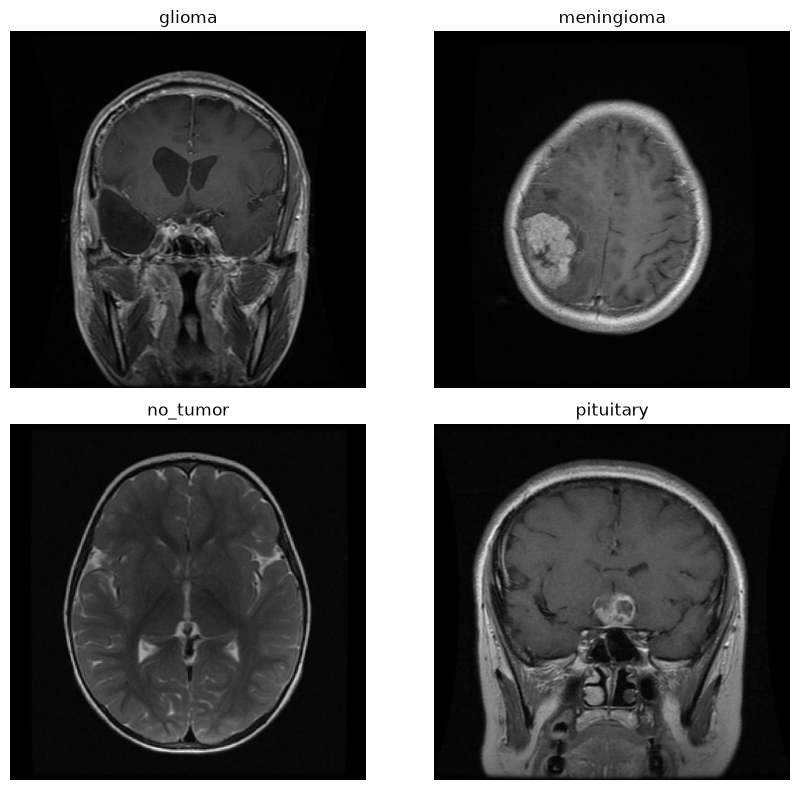

In [ ]:
# Display one representative MRI image from each class.
# This provides a visual check of the image content and class labels before training.
fig, axes= plt.subplots(2,2, figsize=(9,8))#creates grid for 4 plots
for ax, cls in zip(axes.flat, classes):#axes.flat lets us iterate over four plots and this collectively pairs each plot with class
 folder= os.path.join(train_dir, cls)
 files= sorted([
     f for f in os.listdir(folder)
     if f.lower().endswith(
         (".jpg",".jpeg",".png")
     )
 ])
 img= Image.open(
     os.path.join(folder, files[0])
 )
 ax.imshow(img)
 ax.set_title(cls)
 ax.axis("off")
plt.tight_layout()
plt.show()


In [ ]:
# Inspect the dimensions, color mode, and file format of a sample MRI image.
# This verifies the original image properties before preprocessing.
filename= sorted(os.listdir(folder))[0]
img= Image.open(os.path.join(folder, filename))
print("Image size: ",img.size)
print("Image mode: ",img.mode)#whether in rgb, grayscale or others
print("Image format: ",img.format)

Image size:  (640, 640)
Image mode:  RGB
Image format:  JPEG


Original:  (640, 640)
Resized:  (224, 224)


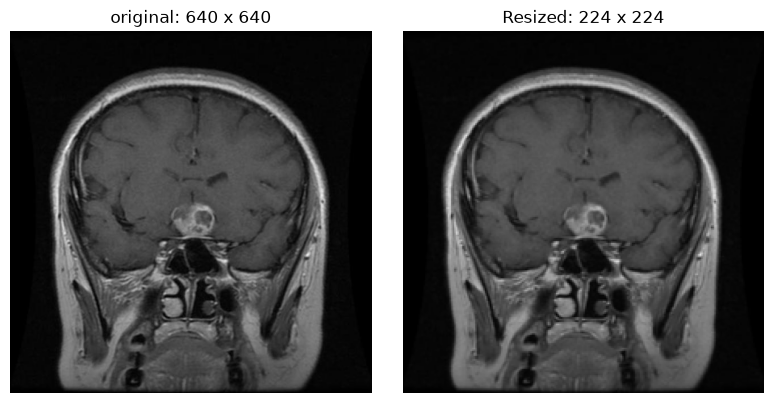

In [ ]:
# Convert the sample image to RGB so every image has three color channels.
# Resize the image to the 224x224 input size required by the models.
# Display the original and resized images to verify the preprocessing step.
img= Image.open(
    os.path.join(folder, filename)
).convert("RGB")# ensures images has three channels
resized_img= img.resize((224,224))
print("Original: ",img.size)
print("Resized: ",resized_img.size)
plt.figure(figsize=(8,4))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title("original: 640 x 640")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(resized_img)
plt.title("Resized: 224 x 224")
plt.axis("off")

plt.tight_layout()
plt.show()



In [ ]:
# Load the training, validation, and test folders as TensorFlow datasets.
# Resize all images to 224x224 and use integer class labels for sparse categorical cross-entropy.
# Shuffle only the training data so validation and test evaluation remain deterministic.

train_ds= tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size= IMG_SIZE,
    batch_size= BATCH_SIZE,
    label_mode= "int",
    shuffle= True,
    seed=42
)
valid_ds= tf.keras.utils.image_dataset_from_directory(
    valid_dir,
    image_size= IMG_SIZE,
    batch_size= BATCH_SIZE,
    label_mode= "int",
    shuffle= False,
)
test_ds= tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size= IMG_SIZE,
    batch_size= BATCH_SIZE,
    label_mode= "int",
    shuffle= False,
)

Found 1695 files belonging to 4 classes.
Found 502 files belonging to 4 classes.
Found 246 files belonging to 4 classes.


In [ ]:
# Inspect one training batch to verify image and label shapes, data type, and pixel range.
# This confirms that the dataset was loaded correctly before model training.
for images, labels in train_ds.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)
    print("Data type:", images.dtype)
    print("Minimum pixel:", tf.reduce_min(images).numpy())
    print("Maximum pixel:", tf.reduce_max(images).numpy())

Image shape: (32, 224, 224, 3)
Label shape: (32,)
Data type: <dtype: 'float32'>
Minimum pixel: 0.0
Maximum pixel: 255.0


In [ ]:
# Create the training-time data augmentation pipeline.
# Apply small rotations, translations, and zoom variations to improve model generalization.

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.02),
    tf.keras.layers.RandomTranslation(
        height_factor=0.03,
        width_factor=0.03
    ),
    tf.keras.layers.RandomZoom(0.05),
])

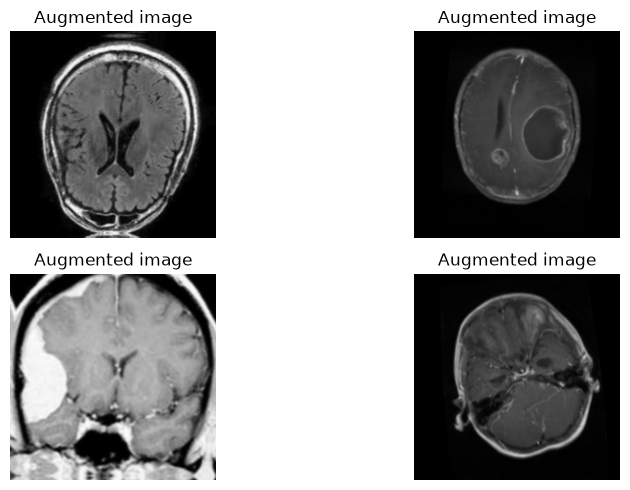

In [ ]:
# Apply augmentation to a few training images and visualize the transformed samples.
# This verifies that the augmentation operations are producing reasonable MRI images.

for images, labels in train_ds.take(1):
    augmented_images = data_augmentation(
        images[:4],
        training=True
    )

    plt.figure(figsize=(10, 5))

    for i in range(4):
        plt.subplot(2, 2, i + 1)
        plt.imshow(
            tf.cast(
                tf.clip_by_value(
                    augmented_images[i], 0, 255
                ),
                tf.uint8
            )
        )
        plt.title("Augmented image")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
# Build the custom CNN used as the baseline model.
# The network uses convolution, batch normalization, ReLU activation, and max pooling to learn image features.
# Global average pooling reduces the final feature maps before the classification layers.
# Dropout is used to reduce overfitting and softmax produces probabilities for the four classes.
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    data_augmentation,
    tf.keras.layers.Rescaling(1./255),

    # Block 1
    tf.keras.layers.Conv2D(32, 3, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D(),

    # Block 2
    tf.keras.layers.Conv2D(64, 3, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D(),

    # Block 3
    tf.keras.layers.Conv2D(128, 3, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D(),

    # Block 4
    tf.keras.layers.Conv2D(256, 3, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D(),

    # Classification
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(4, activation="softmax")
])

In [ ]:
# Display the custom CNN architecture, including layer shapes and parameter counts.
# This is used to verify the model structure before compilation and training.
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 423,268 (1.61 MB)

 Trainable params: 422,308 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

## Flow
Large learning rate

      ↓
Big changes to weights

      ↓
Can learn quickly

      ↓
But may overshoot



Small learning rate

      ↓
Small changes

      ↓
Slower learning

      ↓
More controlled

In [ ]:
# Compile the custom CNN with the Adam optimizer.
# Use a controlled learning rate of 0.0001 for stable weight updates.
# Sparse categorical cross-entropy is appropriate because the dataset uses integer class labels.
# Accuracy is tracked as the main training and validation performance metric.
model.compile(
    optimizer=tf.keras.optimizers.Adam(#responsible for updating the trainable weights of our model.
        learning_rate=0.0001 #controls how big the weight updates are
    ),
    loss="sparse_categorical_crossentropy", #loss function tells us how wrong the prediction is
    metrics=["accuracy"]#calculate classification accuracy so I can monitor it
)

In [ ]:
# Configure callbacks for the custom CNN.
# EarlyStopping stops training when validation loss stops improving and restores the best weights.
# ModelCheckpoint saves the best custom CNN based on validation loss
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "custom_cnn_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

In [ ]:
# Collect all validation labels from the validation dataset.
# Count the number of samples belonging to each validation class.
all_labels = []

for images, labels in valid_ds:
    all_labels.extend(labels.numpy())

all_labels = np.array(all_labels)

for i, class_name in enumerate(valid_ds.class_names):
    print(class_name, ":", np.sum(all_labels == i))

glioma : 161
meningioma : 124
no_tumor : 99
pituitary : 118


In [ ]:
# Collect all training labels from the training dataset.
# Store them as a NumPy array so class frequencies can be used to calculate class weights.
all_train_labels = []

for images, labels in train_ds:
    all_train_labels.extend(labels.numpy())

all_train_labels = np.array(all_train_labels)

In [ ]:
# Calculate balanced class weights from the training labels.
# Class weights reduce the effect of differences in the number of images available for each class.
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(train_ds.class_names)),
    y=all_train_labels
)

class_weights = dict(
    enumerate(class_weights_array)
)

print(class_weights)

{0: np.float64(0.7513297872340425), 1: np.float64(1.183659217877095), 2: np.float64(1.2649253731343284), 3: np.float64(0.9674657534246576)}


In [ ]:
# Train the custom CNN using the training dataset.
# Evaluate after every epoch on the validation dataset and use class weights during training.
# Train for up to 30 epochs while the callbacks control early stopping and checkpointing.
history = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=30,
    callbacks=callbacks,
    class_weight=class_weights
)

Epoch 1/30


c:\Users\veena\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


53/53 ━━━━━━━━━━━━━━━━━━━━ 153s 3s/step - accuracy: 0.5746 - loss: 1.1066 - val_accuracy: 0.3207 - val_loss: 1.3782
Epoch 2/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 139s 3s/step - accuracy: 0.6791 - loss: 0.8757 - val_accuracy: 0.3207 - val_loss: 1.4806
Epoch 3/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 133s 3s/step - accuracy: 0.7091 - loss: 0.7879 - val_accuracy: 0.3247 - val_loss: 1.5557
Epoch 4/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 137s 3s/step - accuracy: 0.7386 - loss: 0.7143 - val_accuracy: 0.3327 - val_loss: 1.6413
Epoch 5/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 132s 2s/step - accuracy: 0.7463 - loss: 0.6808 - val_accuracy: 0.3386 - val_loss: 1.6491
Epoch 6/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 137s 3s/step - accuracy: 0.7723 - loss: 0.6531 - val_accuracy: 0.4442 - val_loss: 1.2996
Epoch 7/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 132s 2s/step - accuracy: 0.7687 - loss: 0.6381 - val_accuracy: 0.2131 - val_loss: 1.4921
Epoch 8/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 135s 3s/step - accuracy: 0.7605 - loss: 0.6300 - val_accuracy: 0.2032 - val_loss: 1.

In [ ]:
# Load the custom CNN checkpoint containing the best validation-loss weights.
# This ensures evaluation uses the best saved version rather than necessarily the final epoch.

best_model = tf.keras.models.load_model("custom_cnn_best.keras")

print("Best model loaded successfully.")

Best model loaded successfully.


In [ ]:
# Evaluate the best custom CNN on the validation and test datasets.
# Print both validation accuracy and test accuracy for model comparison.
val_loss, val_acc = best_model.evaluate(valid_ds, verbose=1)
test_loss, test_acc = best_model.evaluate(test_ds, verbose=1)

print("Validation Accuracy:", val_acc)
print("Test Accuracy:", test_acc)

16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 404ms/step - accuracy: 0.8267 - loss: 0.4607
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 467ms/step - accuracy: 0.8049 - loss: 0.5049
Validation Accuracy: 0.8266932368278503
Test Accuracy: 0.8048780560493469


In [ ]:
# Generate predictions for every test image using the best custom CNN.
# Store the true labels and predicted class indices.
# Print precision, recall, F1-score, and support for each tumor class.
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = best_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print(classification_report(
    y_true,
    y_pred,
    target_names=test_ds.class_names,
    digits=4
))

              precision    recall  f1-score   support

      glioma     0.7723    0.9750    0.8619        80
  meningioma     0.9259    0.3968    0.5556        63
    no_tumor     0.7015    0.9592    0.8103        49
   pituitary     0.9412    0.8889    0.9143        54

    accuracy                         0.8049       246
   macro avg     0.8352    0.8050    0.7855       246
weighted avg     0.8346    0.8049    0.7847       246



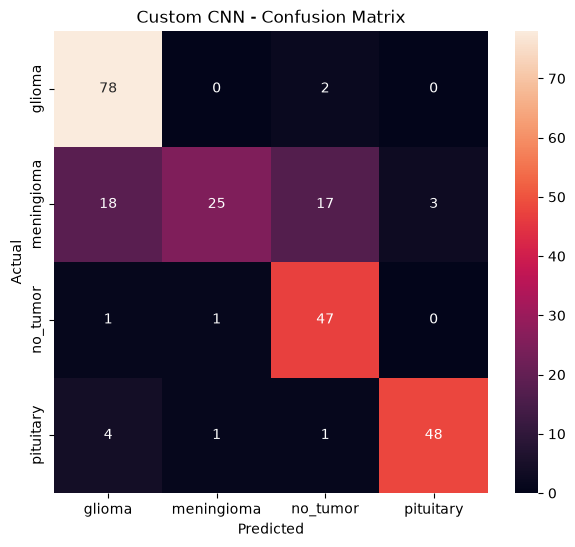

In [ ]:
# Calculate the custom CNN confusion matrix.
# Visualize actual versus predicted classes to identify class-specific errors.
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=test_ds.class_names,
    yticklabels=test_ds.class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Custom CNN - Confusion Matrix")
plt.show()

In [ ]:
# Load MobileNetV2 with ImageNet pretrained weights and remove its original classification head.
# Freeze the pretrained base so it initially acts as a feature extractor.
# This creates the starting point for transfer learning.
base_model= MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)
base_model.trainable= False
print("MobileNetV2 model loaded successfully.")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
MobileNetV2 model loaded successfully.


## Flow
MobileNetV2 output

        ↓
Feature maps

        ↓
GlobalAveragePooling2D

        ↓
Feature vector

        ↓
Dense layer

In [ ]:
# Build the initial MobileNetV2 transfer-learning classifier.
# Apply the same training augmentation pipeline used by the custom CNN.
# Convert image values using MobileNetV2 preprocessing.
# Use the frozen MobileNetV2 feature extractor followed by a custom classification head for four classes.
transfer_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    tf.keras.layers.Lambda(
        tf.keras.applications.mobilenet_v2.preprocess_input #preprocess_input transforms those values into the format MobileNetV2 was trained with.
    ),

    base_model,

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(128, activation="relu"),

    tf.keras.layers.Dropout(0.4),

    tf.keras.layers.Dense(4, activation="softmax")
])

In [ ]:

transfer_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## flow
compile()

       ↓

Tell model HOW to learn

       ↓

fit()

       ↓    
Actually learn from MRI images

In [35]:
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [36]:
transfer_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint( #Whenever validation loss improves, the model is saved:
        "mobilenetv2_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

In [37]:
history_transfer = transfer_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=20,
    callbacks=transfer_callbacks,
    class_weight=class_weights
)

c:\Users\veena\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 63s 984ms/step - accuracy: 0.5233 - loss: 1.1507 - val_accuracy: 0.6514 - val_loss: 0.8318
Epoch 2/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 54s 1s/step - accuracy: 0.7021 - loss: 0.7765 - val_accuracy: 0.7092 - val_loss: 0.6970
Epoch 3/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 54s 1s/step - accuracy: 0.7758 - loss: 0.6193 - val_accuracy: 0.7211 - val_loss: 0.6642
Epoch 4/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 74s 860ms/step - accuracy: 0.7888 - loss: 0.5554 - val_accuracy: 0.7251 - val_loss: 0.6338
Epoch 5/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 48s 908ms/step - accuracy: 0.8283 - loss: 0.4867 - val_accuracy: 0.7649 - val_loss: 0.5975
Epoch 6/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 49s 917ms/step - accuracy: 0.8407 - loss: 0.4435 - val_accuracy: 0.7749 - val_loss: 0.5740
Epoch 7/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 38s 722ms/step - accuracy: 0.8490 - loss: 0.4242 - val_accuracy: 0.7829 - val_loss: 0.5556
Epoch 8/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 40s 758ms/step - accuracy: 0.8678 - loss: 0.3825 - val_accuracy: 

In [38]:
val_loss, val_acc = transfer_model.evaluate(
    valid_ds,
    verbose=1
)

test_loss, test_acc = transfer_model.evaluate(
    test_ds,
    verbose=1
)

print("Validation Accuracy:", val_acc)
print("Test Accuracy:", test_acc)

16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 546ms/step - accuracy: 0.8327 - loss: 0.4651
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 519ms/step - accuracy: 0.8252 - loss: 0.4469
Validation Accuracy: 0.8326693177223206
Test Accuracy: 0.8252032399177551


In [39]:
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = transfer_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print(classification_report(
    y_true,
    y_pred,
    target_names=classes
))

              precision    recall  f1-score   support

      glioma       0.95      0.90      0.92        80
  meningioma       0.84      0.65      0.73        63
    no_tumor       0.95      0.73      0.83        49
   pituitary       0.65      1.00      0.79        54

    accuracy                           0.83       246
   macro avg       0.85      0.82      0.82       246
weighted avg       0.85      0.83      0.83       246



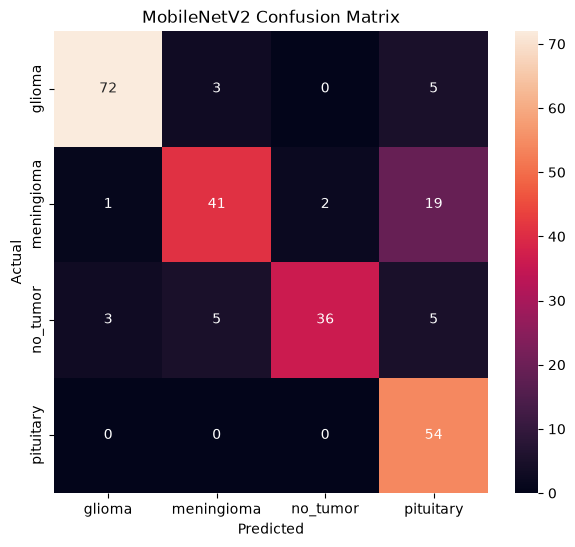

In [40]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("MobileNetV2 Confusion Matrix")
plt.show()

# Final Transfer Learning Model

The initial MobileNetV2 implementation used a Lambda layer for preprocessing.
For reliable model serialization and deployment, the preprocessing was replaced
with a Keras Rescaling layer equivalent to MobileNetV2's [-1, 1] input scaling.

In [ ]:
# Build a deployment-safe version of the MobileNetV2 transfer-learning model.
# Replace the Lambda preprocessing layer with Keras Rescaling so the model can be serialized and loaded reliably.
# Rescaling maps pixel values from 0-255 to the -1 to 1 range expected by MobileNetV2.
transfer_model_fixed = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    # Equivalent to MobileNetV2 preprocess_input: [0,255] -> [-1,1]
    tf.keras.layers.Rescaling(1./127.5, offset=-1),

    base_model,

    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(4, activation="softmax")
])

In [ ]:
# Copy the trained weights from the original transfer-learning model into the serialization-safe model.
# This keeps the learned feature extractor and classification-head weights unchanged.
transfer_model_fixed.set_weights(transfer_model.get_weights())

In [43]:
transfer_model_fixed.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [44]:
val_loss, val_acc = transfer_model_fixed.evaluate(valid_ds, verbose=1)

test_loss, test_acc = transfer_model_fixed.evaluate(test_ds, verbose=1)

print("Validation Accuracy:", val_acc)
print("Test Accuracy:", test_acc)

16/16 ━━━━━━━━━━━━━━━━━━━━ 13s 530ms/step - accuracy: 0.8327 - loss: 0.4651
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 510ms/step - accuracy: 0.8252 - loss: 0.4469
Validation Accuracy: 0.8326693177223206
Test Accuracy: 0.8252032399177551


# Fine-Tuning MobileNetV2

The pretrained MobileNetV2 base is partially unfrozen so that the upper layers
can adapt to MRI-specific features while the lower-level features remain frozen.

In [ ]:
# Unfreeze the MobileNetV2 base so selected pretrained layers can be fine-tuned for MRI-specific features.
# Freeze all but the last 30 base-model layers to limit the number of updated pretrained parameters.
# Keep BatchNormalization layers frozen for more stable fine-tuning.

base_model.trainable = True

# Freeze all but the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

In [46]:
transfer_model_fixed.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 1,675,204 (6.39 MB)

 Non-trainable params: 747,264 (2.85 MB)

In [47]:
transfer_model_fixed.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [48]:
fine_tune_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "mobilenetv2_finetuned_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

In [49]:
history_finetune = transfer_model_fixed.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=10,
    callbacks=fine_tune_callbacks,
    class_weight=class_weights
)

Epoch 1/10


c:\Users\veena\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


53/53 ━━━━━━━━━━━━━━━━━━━━ 69s 1s/step - accuracy: 0.9263 - loss: 0.2176 - val_accuracy: 0.8625 - val_loss: 0.4438
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 55s 1s/step - accuracy: 0.9274 - loss: 0.1944 - val_accuracy: 0.8665 - val_loss: 0.3856
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 57s 1s/step - accuracy: 0.9381 - loss: 0.1954 - val_accuracy: 0.8904 - val_loss: 0.3707
Epoch 4/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.9493 - loss: 0.1576 - val_accuracy: 0.8486 - val_loss: 0.4469
Epoch 5/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 53s 999ms/step - accuracy: 0.9534 - loss: 0.1439 - val_accuracy: 0.8586 - val_loss: 0.4411
Epoch 6/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 78s 1s/step - accuracy: 0.9599 - loss: 0.1220 - val_accuracy: 0.8506 - val_loss: 0.4613


In [50]:
val_loss, val_acc = transfer_model_fixed.evaluate(
    valid_ds,
    verbose=1
)

test_loss, test_acc = transfer_model_fixed.evaluate(
    test_ds,
    verbose=1
)

print("Validation Accuracy:", val_acc)
print("Validation Loss:", val_loss)

print("Test Accuracy:", test_acc)
print("Test Loss:", test_loss)

16/16 ━━━━━━━━━━━━━━━━━━━━ 12s 763ms/step - accuracy: 0.8904 - loss: 0.3707
8/8 ━━━━━━━━━━━━━━━━━━━━ 7s 806ms/step - accuracy: 0.8821 - loss: 0.3615
Validation Accuracy: 0.8904382586479187
Validation Loss: 0.370735764503479
Test Accuracy: 0.8821138143539429
Test Loss: 0.3614976108074188


# Final Model Evaluation

In [51]:


class_names = ['glioma', 'meningioma', 'no_tumor', 'pituitary']

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = transfer_model_fixed.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

      glioma       0.94      0.90      0.92        80
  meningioma       0.82      0.81      0.82        63
    no_tumor       0.95      0.82      0.88        49
   pituitary       0.83      1.00      0.91        54

    accuracy                           0.88       246
   macro avg       0.89      0.88      0.88       246
weighted avg       0.89      0.88      0.88       246



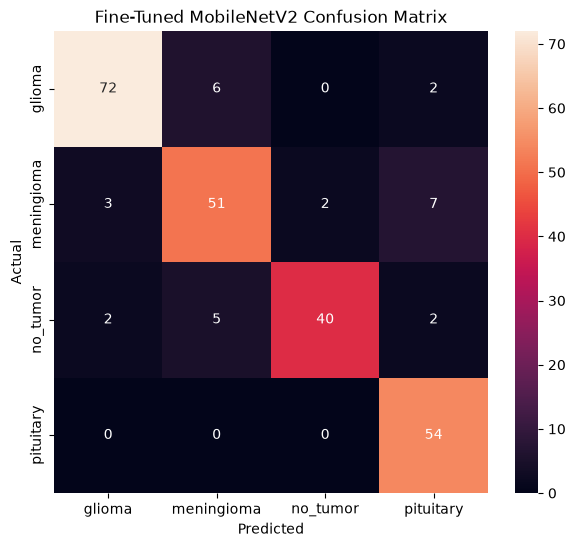

In [52]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Fine-Tuned MobileNetV2 Confusion Matrix")

plt.show()

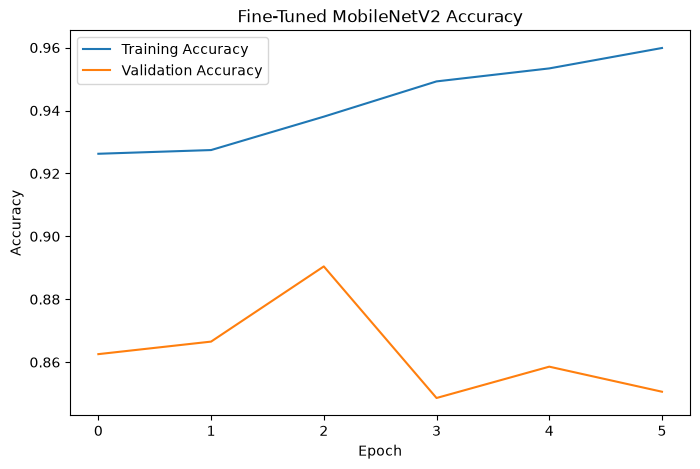

In [ ]:
# Plot training and validation accuracy across fine-tuning epochs.
# Use this curve to inspect learning progress and possible overfitting.
plt.figure(figsize=(8, 5))

plt.plot(history_finetune.history["accuracy"], label="Training Accuracy")
plt.plot(history_finetune.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Fine-Tuned MobileNetV2 Accuracy")
plt.legend()
plt.show()

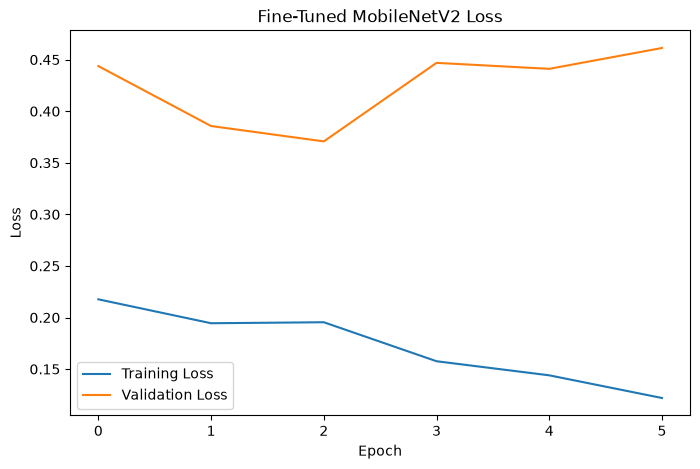

In [ ]:
# Plot training and validation loss across fine-tuning epochs.
# Use this curve to inspect convergence and generalization during fine-tuning.
plt.figure(figsize=(8, 5))

plt.plot(history_finetune.history["loss"], label="Training Loss")
plt.plot(history_finetune.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Fine-Tuned MobileNetV2 Loss")
plt.legend()
plt.show()

# Save and Verify Final Model

In [ ]:
# Save the final fine-tuned MobileNetV2 model in Keras format.
transfer_model_fixed.save("brain_tumor_mobilenetv2_final.keras")

In [ ]:
# Save the final fine-tuned MobileNetV2 model in H5 format.
transfer_model_fixed.save("brain_tumor_mobilenetv2_final.h5")

In [ ]:
# Reload the saved H5 model to verify that the exported deployment file can be loaded successfully.
# Evaluate the reloaded model on the test set to confirm that its performance is preserved.
loaded_model = tf.keras.models.load_model(
    "brain_tumor_mobilenetv2_final.h5"
)

test_loss, test_acc = loaded_model.evaluate(
    test_ds,
    verbose=1
)

print("Loaded Model Test Accuracy:", test_acc)

8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 567ms/step - accuracy: 0.8821 - loss: 0.3615
Loaded Model Test Accuracy: 0.8821138143539429


# Model Comparison and Final Model Selection

Three models were developed and evaluated for the brain tumor MRI classification task:

1. **Custom CNN**
2. **MobileNetV2 with Transfer Learning**
3. **Fine-Tuned MobileNetV2**

The models were evaluated on the same validation and test datasets containing four classes:

- Glioma
- Meningioma
- No Tumor
- Pituitary

The main evaluation criteria were validation accuracy, test accuracy, validation loss, test loss, and classification performance.

---

## Model Performance Comparison

| Model | Validation Accuracy | Validation Loss | Test Accuracy | Test Loss |
|---|---:|---:|---:|---:|
| Custom CNN | 82.67% | 0.4607 | 80.48% | 0.5049 |
| MobileNetV2 (Transfer Learning) | 83.27% | 0.4651 | 82.52% | 0.4469 |
| **Fine-Tuned MobileNetV2** | **89.04%** | **0.3707** | **88.21%** | **0.3615** |

---

## Comparison of Results

### 1. Custom CNN

The custom CNN achieved a test accuracy of **80.48%**.

It successfully learned meaningful features from the MRI images, but its performance was lower than the transfer learning approaches. This indicates that learning all visual features from the available dataset was less effective than using features learned from a large pretrained dataset.

**Test Accuracy:** 80.48%

---

### 2. MobileNetV2 with Transfer Learning

The pretrained MobileNetV2 achieved a test accuracy of **82.52%**, improving over the custom CNN.

The pretrained ImageNet features provided a stronger starting point for image classification. However, the base MobileNetV2 feature extractor was frozen during this stage, limiting its ability to adapt its learned features specifically to brain MRI images.

**Test Accuracy:** 82.52%

---

### 3. Fine-Tuned MobileNetV2

The fine-tuned MobileNetV2 achieved the best overall performance:

- **Validation Accuracy:** 89.04%
- **Validation Loss:** 0.3707
- **Test Accuracy:** 88.21%
- **Test Loss:** 0.3615
- **Macro F1-score:** 0.88
- **Weighted F1-score:** 0.88

Fine-tuning allowed the pretrained MobileNetV2 features to adapt to the characteristics of brain MRI images, resulting in a substantial improvement over both the custom CNN and the frozen transfer-learning model.

---

## Test Accuracy Comparison

The improvement in test accuracy can be summarized as follows:

| Model | Test Accuracy | Improvement over Custom CNN |
|---|---:|---:|
| Custom CNN | 80.48% | — |
| MobileNetV2 | 82.52% | +2.04 percentage points |
| **Fine-Tuned MobileNetV2** | **88.21%** | **+7.73 percentage points** |

The fine-tuned MobileNetV2 improved test accuracy by **7.73 percentage points** compared with the custom CNN and by **5.69 percentage points** compared with the frozen MobileNetV2.

---

## Final Model Classification Performance

The classification report of the fine-tuned MobileNetV2 on the test dataset was:

| Class | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Glioma | 0.94 | 0.90 | 0.92 | 80 |
| Meningioma | 0.82 | 0.81 | 0.82 | 63 |
| No Tumor | 0.95 | 0.82 | 0.88 | 49 |
| Pituitary | 0.83 | 1.00 | 0.91 | 54 |
| **Macro Average** | **0.89** | **0.88** | **0.88** | **246** |
| **Weighted Average** | **0.89** | **0.88** | **0.88** | **246** |

The model achieved a balanced overall classification performance, with a macro F1-score of **0.88**.

The strongest recall was obtained for the **pituitary** class, with a recall of **1.00**, meaning all pituitary images in the test set were correctly identified.

---

## Final Model Selection

Based on the evaluation results, the **Fine-Tuned MobileNetV2** was selected as the final deployment model.

The reasons for selecting this model are:

- Highest validation accuracy: **89.04%**
- Highest test accuracy: **88.21%**
- Lowest test loss among the three models: **0.3615**
- Strong and balanced classification performance
- Macro F1-score of **0.88**
- Better adaptation to the brain MRI classification task through fine-tuning

Therefore, the fine-tuned MobileNetV2 will be used as the final model for the Streamlit application.

---

## Final Decision

**Selected Model: Fine-Tuned MobileNetV2**

**Final Test Accuracy: 88.21%**

The trained final model is saved as:

`brain_tumor_mobilenetv2_final.h5`

This model will be used for deployment in the Streamlit application.

> **Note:** The reported performance is based on the available dataset and test split. This application is intended as an educational machine-learning prototype and should not be used as a substitute for professional medical diagnosis.

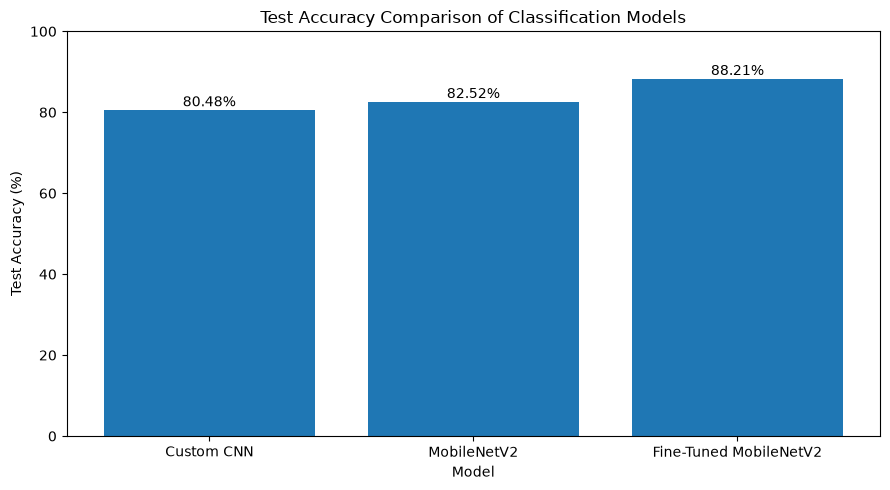

In [58]:
models = ["Custom CNN", "MobileNetV2", "Fine-Tuned MobileNetV2"]
test_accuracy = [80.48, 82.52, 88.21]

plt.figure(figsize=(9, 5))
bars = plt.bar(models, test_accuracy)

plt.ylabel("Test Accuracy (%)")
plt.xlabel("Model")
plt.title("Test Accuracy Comparison of Classification Models")
plt.ylim(0, 100)

for bar, value in zip(bars, test_accuracy):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [1]:
import sys
print(sys.executable)
print(sys.version)

c:\Users\veena\AppData\Local\Programs\Python\Python311\python.exe
3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]


In [2]:
import tensorflow as tf
print(tf.__version__)

ImportError: DLL load failed while importing _pywrap_tf_session: An Application Control policy has blocked this file.